# Use k-means to classify network events into normal and abnormal categories.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

In [2]:
columns = ["duration", "protocol_type", "service", "flag", "src_bytes", "dst_bytes", "land",
           "wrong_fragment", "urgent", "hot", "num_failed_logins", "logged_in", "num_compromised",
           "root_shell", "su_attempted", "num_root", "num_file_creations", "num_shells",
           "num_access_files", "num_outbound_cmds", "is_host_login", "is_guest_login", "count",
           "srv_count", "serror_rate", "srv_serror_rate", "rerror_rate", "srv_rerror_rate",
           "same_srv_rate", "diff_srv_rate", "srv_diff_host_rate", "dst_host_count",
           "dst_host_srv_count", "dst_host_same_srv_rate", "dst_host_diff_srv_rate",
           "dst_host_same_src_port_rate", "dst_host_srv_diff_host_rate", "dst_host_serror_rate",
           "dst_host_srv_serror_rate", "dst_host_rerror_rate", "dst_host_srv_rerror_rate",
           "attack", "difficulty"]

df = pd.read_csv("KDDTrain+_20Percent.txt", names=columns)
print(df.shape)

(25192, 43)


In [3]:
df["label"] = (df["attack"] != "normal").astype(int)
print(df["label"].value_counts())

label
0    13449
1    11743
Name: count, dtype: int64


In [4]:
X = df.drop(columns=["attack", "difficulty", "label"])
for col in ["protocol_type", "service", "flag"]:          # text columns -> numbers
    X[col] = LabelEncoder().fit_transform(X[col])
X_scaled = StandardScaler().fit_transform(X)              # k-means needs scaled data
y = df["label"]

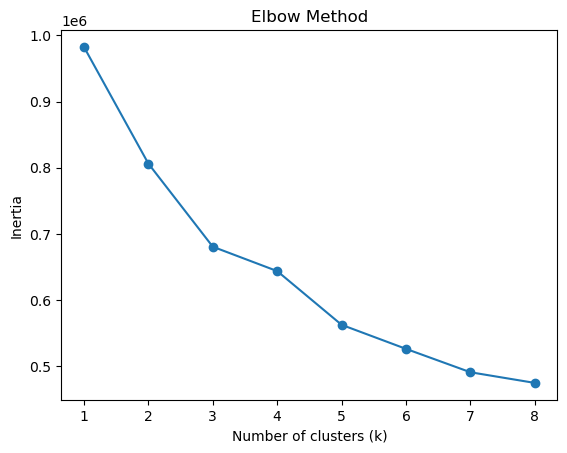

In [5]:
inertia = []
for k in range(1, 9):
    inertia.append(KMeans(n_clusters=k, random_state=42, n_init=10).fit(X_scaled).inertia_)
plt.plot(range(1, 9), inertia, marker="o")
plt.title("Elbow Method")
plt.xlabel("Number of clusters (k)"); plt.ylabel("Inertia")
plt.show()

In [6]:
kmeans = KMeans(n_clusters=2, random_state=42, n_init=10)
clusters = kmeans.fit_predict(X_scaled)

In [7]:
# K-means doesn't know which cluster is "normal", so map each cluster
# to the majority true label inside it (labels used only for evaluation)
mapping = pd.Series(y.values).groupby(clusters).agg(lambda s: s.mode()[0]).to_dict()
pred = pd.Series(clusters).map(mapping)
print("Cluster -> label mapping:", mapping)

Cluster -> label mapping: {0: 0, 1: 1}



Accuracy: 0.905
              precision    recall  f1-score   support

      Normal       0.85      0.99      0.92     13449
    Abnormal       0.99      0.81      0.89     11743

    accuracy                           0.90     25192
   macro avg       0.92      0.90      0.90     25192
weighted avg       0.92      0.90      0.90     25192



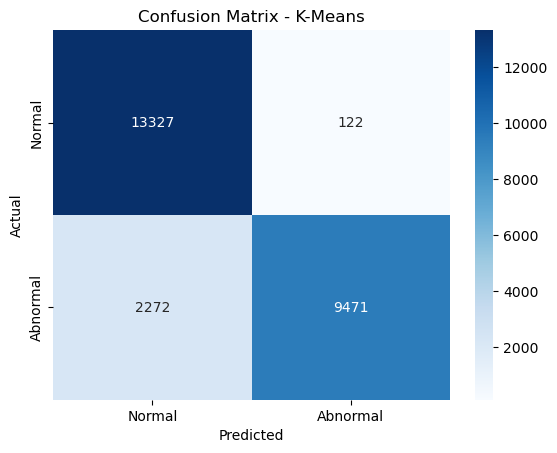

In [8]:
print("\nAccuracy:", round(accuracy_score(y, pred), 4))
print(classification_report(y, pred, target_names=["Normal", "Abnormal"]))

sns.heatmap(confusion_matrix(y, pred), annot=True, fmt="d", cmap="Blues",
            xticklabels=["Normal", "Abnormal"], yticklabels=["Normal", "Abnormal"])
plt.title("Confusion Matrix - K-Means")
plt.xlabel("Predicted"); plt.ylabel("Actual")
plt.show()

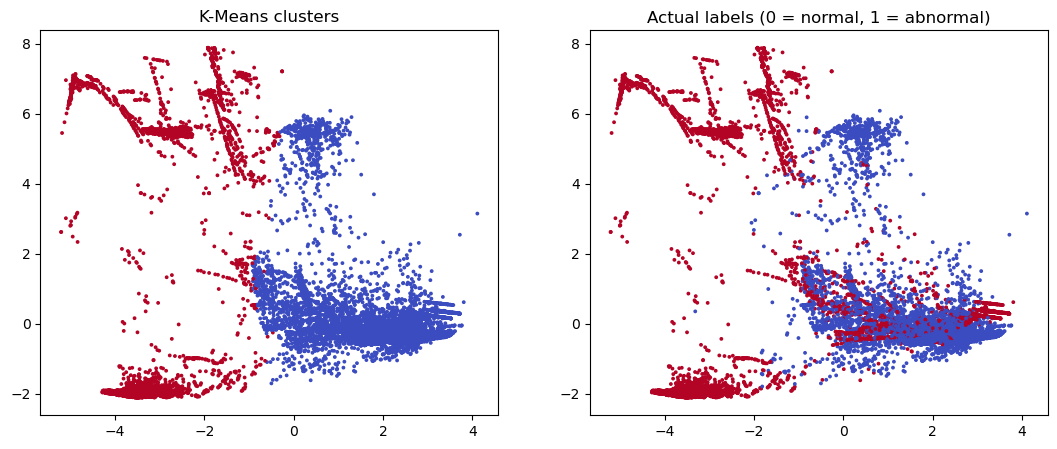

In [9]:
X_2d = PCA(n_components=2).fit_transform(X_scaled)
fig, ax = plt.subplots(1, 2, figsize=(13, 5))
ax[0].scatter(X_2d[:, 0], X_2d[:, 1], c=clusters, cmap="coolwarm", s=3)
ax[0].set_title("K-Means clusters")
ax[1].scatter(X_2d[:, 0], X_2d[:, 1], c=y, cmap="coolwarm", s=3)
ax[1].set_title("Actual labels (0 = normal, 1 = abnormal)")
plt.show()

In [10]:
print(pd.crosstab(df["attack"], pred.map({0: "Normal", 1: "Abnormal"})))

col_0            Abnormal  Normal
attack                           
back                    0     196
buffer_overflow         0       6
ftp_write               0       1
guess_passwd           10       0
imap                    0       5
ipsweep                84     626
land                    0       1
loadmodule              0       1
multihop                0       2
neptune              8281       1
nmap                   42     259
normal                122   13327
phf                     0       2
pod                     0      38
portsweep             583       4
rootkit                 0       4
satan                 456     235
smurf                   0     529
spy                     0       1
teardrop               15     173
warezclient             0     181
warezmaster             0       7
